# 02 — Taxa manual

**Pergunta de negócio.** Para um grupo sem histórico próprio (cotação nova), qual a mortalidade esperada
em relação à BR-EMSmt 2026, e quais características do grupo mudam esse nível?

**Modelo.** Em cada célula (estipulante × faixa etária × sexo × setor × faixa de capital × porte):

N ~ Poisson(μ), com log μ = log E + β₀ + efeitos dos fatores,

em que E são os óbitos esperados pela tábua. exp(β) é um fator A/E relativo; o nível base de cada fator
é o de maior exposição.

**Decisões (justificadas ao longo do notebook):**
1. Estima-se em **contagem de óbitos**, não em valor: em R$, poucos sinistros de capital alto dominariam
   os fatores. O valor entra na renovação (Etapa 3), com pooling de sinistros grandes.
2. Só entra experiência **maturada** (até 12 meses antes da data de referência), para o IBNR não puxar os
   fatores para baixo.
3. O modelo tem **efeito aleatório de estipulante** (Poisson-Gama): separa o efeito do setor do efeito do
   grupo, dá intervalos honestos e estima o k de credibilidade da renovação.
4. **Setor e faixa de capital são fatores de tarifa por decisão de negócio**, estimados com
   **encolhimento** calibrado nos dados (com pouca evidência, o fator fica perto de 1). Idade, sexo e porte
   só entram com evidência estatística. A seção 7 mostra por que a seleção puramente estatística não
   serve para os fatores centrais.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing import manual as M
from vgpricing import verdade as V

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg, cm, cs = carregar_config("base", RAIZ), carregar_config("manual", RAIZ), carregar_config("sintetico", RAIZ)
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")
    tabua = obter_tabua(cfg, RAIZ)
assert not tabua.placeholder, "Tábua oficial não carregada"

pasta = RAIZ / "data/synthetic"
if not (pasta / "limpo").exists():
    raise FileNotFoundError("Rode antes o notebook 01_dados (ele grava a base limpa em data/synthetic/limpo).")
dados = {t: pd.read_parquet(pasta / "limpo" / f"{t}.parquet") for t in ("estipulantes", "vidas", "sinistros")}
verdade = pd.read_parquet(pasta / "verdade_estipulantes.parquet")        # só existe no sintético
verdade_vidas = pd.read_parquet(pasta / "verdade_vidas.parquet")
print(f"Tábua: {tabua.nome} | estipulantes: {len(dados['estipulantes'])} | segmentos de vida: {len(dados['vidas']):,}")

Tábua: BR-EMSmt-2026 | estipulantes: 250 | segmentos de vida: 711,103


## 1. Base de modelagem

In [2]:
cel, info = M.base_modelagem(dados["vidas"], dados["sinistros"], dados["estipulantes"], tabua,
                             cfg["data_referencia"], cm, cfg["exposicao"]["dias_por_ano"])
pd.Series({k: v for k, v in info.items() if k != "ids_sem_celula"}).to_frame("valor")

,valor
corte_experiencia,2024-12-31
sinistros_no_periodo,1424
sinistros_sem_celula,21
celulas_sexo_ND_removidas,1045
celulas,6440
obitos,1396
esperados,"1,443.2470"


Sinistros "sem célula" são de vidas sem exposição limpa na data do óbito (vida inexistente no cadastro,
ou segmento excluído na validação). Ficam fora do modelo e estão listados em `info["ids_sem_celula"]` para
investigação. Células com sexo ausente também ficam fora.

## 2. Primeira leitura: A/E por fator, sem ajuste

In [3]:
F = cm["fatores"]
uni = pd.concat([cel.groupby(f, observed=True)[["E", "N"]].sum().assign(fator=f).rename_axis("nivel").reset_index()
                 for f in F])
uni["A/E"] = uni["N"] / uni["E"]
uni[["fator", "nivel", "E", "N", "A/E"]]

,fator,nivel,E,N,A/E
0,faixa_idade,30-39,268.9079,267,0.9929
1,faixa_idade,40-49,439.8466,421,0.9572
2,faixa_idade,50-59,404.6047,396,0.9787
3,faixa_idade,60+,201.8413,208,1.0305
4,faixa_idade,ate29,128.0465,104,0.8122
0,sexo,F,454.8225,410,0.9015
1,sexo,M,988.4245,986,0.9975
0,setor,adm_publica,300.3063,263,0.8758
1,setor,comercio,124.1389,106,0.8539
2,setor,construcao,106.7399,138,1.2929


O A/E univariado mistura efeitos (um setor com grupos de capital alto parece melhor também por causa do
capital). O modelo multivariado separa isso.

## 3. GLM Poisson, Binomial Negativa e onde está a sobredispersão

In [4]:
glm = M.ajustar_glm(cel, F)
nb = M.teste_binomial_negativa(cel, F, glm)
pd.Series({"deviance": glm.extra["deviance"], "gl": glm.extra["gl"],
           "dispersão de Pearson": glm.extra["dispersao_pearson"],
           "alpha NB2": nb["alpha_nb2"], "LR NB2 vs Poisson": nb["estatistica_lr"],
           "p-valor (mistura 50:50)": nb["p_valor"]}).to_frame("valor")

,valor
deviance,"2,604.1445"
gl,"6,421.0000"
dispersão de Pearson,1.8573
alpha NB2,0.0714
LR NB2 vs Poisson,5.2412
p-valor (mistura 50:50),0.0110


Há sobredispersão em relação à Poisson. A Binomial Negativa (NB2) trata isso como ruído independente
**por célula**. A fonte real, porém, é conhecida: grupos diferentes têm mortalidades diferentes, e todas as
células de um grupo compartilham esse desvio. O Poisson-Gama coloca a dispersão **no grupo**. NB2 e
Poisson-Gama não são aninhados, então a comparação é por AIC, com as log-verossimilhanças na mesma base
(incluindo o termo −log N!).

In [5]:
M.comparar_dispersao(cel, F)

,modelo,onde fica a dispersão,loglik,parametros,AIC,dif_AIC_vs_melhor
0,Poisson,nenhuma,"-2,197.1490",19,"4,432.2979",41.7316
1,Binomial Negativa (NB2),célula (independente),"-2,194.5284",20,"4,429.0567",38.4903
2,Poisson-Gama,estipulante (compartilhada pelas células),"-2,175.2832",20,"4,390.5664",0.0000


Com o mesmo número de parâmetros, o Poisson-Gama tem AIC bem menor: a dispersão está no grupo, não na
célula. Isso tem consequência prática: a NB2 subestima a incerteza dos fatores (seção 8).

## 4. Poisson-Gama: efeito aleatório de estipulante

Cada estipulante tem um fator u ~ Gama(média 1, variância 1/k). A verossimilhança marginal tem forma
fechada (sem aproximação numérica), e a média a posteriori de u é exatamente a fórmula de credibilidade:

E[u | dados] = Z · (N/M) + (1 − Z),   Z = M / (M + k),

em que M são os óbitos esperados pela taxa manual. **k é medido em óbitos esperados**: um grupo com M = k
recebe 50% de credibilidade.

**Como o k é obtido.** Não é escolhido à mão: é estimado por máxima verossimilhança marginal, junto com os
fatores. **Isto é Bayes empírico, não bayesiano completo.** A regra de Bayes é usada para o fator de cada
grupo (a Gama faz o papel de priori), mas o k é estimado nos dados e tratado como conhecido. A incerteza do
próprio k (o intervalo abaixo) não é propagada para o preço; isso é o papel da camada bayesiana (Etapa 4).
A comparação com o k de Bühlmann-Straub em forma fechada (estimador de momentos) fica na Etapa 3.

In [6]:
pg = M.ajustar_poisson_gama(cel, F, beta_inicial=glm.beta)
k_verdade = 1 / (np.exp(cs["sigma_efeito_grupo"] ** 2) - 1)
pd.Series({"k estimado": pg.extra["k"], "IC 95% inferior": pg.extra["ic_k"][0], "IC 95% superior": pg.extra["ic_k"][1],
           "CV do efeito de grupo": pg.extra["cv_efeito_grupo"],
           "k implícito na hipótese do gerador": k_verdade}).to_frame("valor")

,valor
k estimado,9.3405
IC 95% inferior,5.4223
IC 95% superior,16.0899
CV do efeito de grupo,0.3272
k implícito na hipótese do gerador,10.6186


In [7]:
taxa = cel["E"].sum() / cel["exposicao"].sum()       # óbitos esperados por vida-ano na carteira
k = pg.extra["k"]
print(f"Mortalidade média esperada: {1000 * taxa:.2f} por mil vidas-ano")
print(f"Z = 50%: ~{k:.0f} óbitos esperados  ≈ {k / taxa:,.0f} vidas-ano")
print(f"Z = 80%: ~{4 * k:.0f} óbitos esperados ≈ {4 * k / taxa:,.0f} vidas-ano")
lo, hi = pg.extra["ic_k"]
print(f"Grupo com 10 óbitos esperados: Z entre {10 / (10 + hi):.0%} e {10 / (10 + lo):.0%} conforme o k no seu IC")

Mortalidade média esperada: 1.77 por mil vidas-ano
Z = 50%: ~9 óbitos esperados  ≈ 5,269 vidas-ano
Z = 80%: ~37 óbitos esperados ≈ 21,077 vidas-ano
Grupo com 10 óbitos esperados: Z entre 38% e 65% conforme o k no seu IC


Em termos de negócio: um grupo precisa de milhares de vidas-ano para que a própria experiência pese
metade. A maioria dos grupos de vida fica longe disso, o que explica por que a taxa manual pesa tanto na
renovação. A última linha mostra quanto a incerteza do k mexe na credibilidade: é ela que a Etapa 4 vai
propagar.

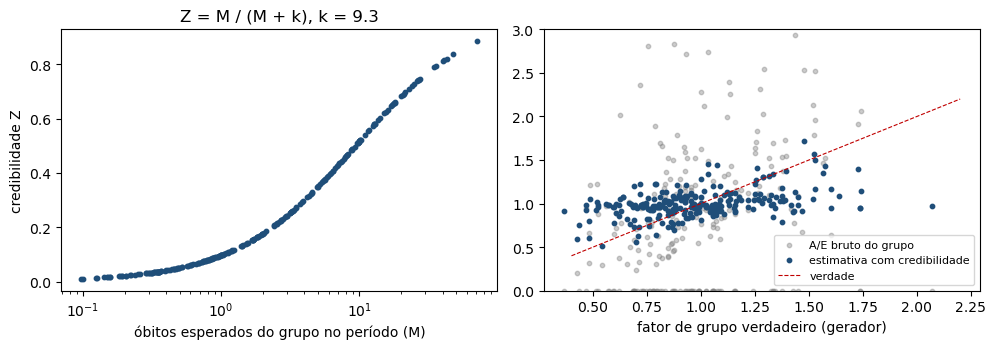

Erro (RMSE em log, ponderado por M): A/E bruto = 0.648 | com credibilidade = 0.204


In [8]:
g = pg.extra["grupos"].merge(verdade[["id_estipulante", "fator_grupo"]], on="id_estipulante")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].scatter(g["M"], g["Z"], s=10, color="#1f4e79"); ax[0].set_xscale("log")
ax[0].set_xlabel("óbitos esperados do grupo no período (M)"); ax[0].set_ylabel("credibilidade Z")
ax[0].set_title(f"Z = M / (M + k), k = {pg.extra['k']:.1f}")
ae_bruto = g["N"] / g["M"]
ax[1].scatter(g["fator_grupo"], ae_bruto, s=10, alpha=0.4, color="grey", label="A/E bruto do grupo")
ax[1].scatter(g["fator_grupo"], g["fator_grupo_posteriori"], s=10, color="#1f4e79", label="estimativa com credibilidade")
ax[1].plot([0.4, 2.2], [0.4, 2.2], ls="--", color="#c00000", lw=0.8, label="verdade")
ax[1].set_ylim(0, 3); ax[1].set_xlabel("fator de grupo verdadeiro (gerador)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
erro = lambda x: np.sqrt(np.average((np.log(x.clip(0.05)) - np.log(g["fator_grupo"])) ** 2, weights=g["M"]))
print(f"Erro (RMSE em log, ponderado por M): A/E bruto = {erro(ae_bruto):.3f} | com credibilidade = {erro(g['fator_grupo_posteriori']):.3f}")

O gráfico da direita é o argumento da Etapa 3 em uma imagem: o A/E bruto de grupos pequenos espalha
muito (inclusive zeros), e a estimativa com credibilidade fica bem mais perto do fator verdadeiro.

## 5. Ridge (penalização de todos os fatores) com λ escolhido deixando grupos de fora

In [9]:
cvl = M.escolher_lambda(cel, F, cm["ridge"]["lambdas"], cm["ridge"]["folds"], cm["semente_cv"])
lam = float(cvl.loc[cvl["deviance_fora_amostra"].idxmin(), "lambda"])
rid = M.ajustar_ridge(cel, F, lam)
print("lambda escolhido:", lam); cvl

lambda escolhido: 100.0


,lambda,deviance_fora_amostra,dif_vs_melhor
0,0.0000,459.1013,14.8647
1,1.0000,458.4535,14.2168
2,3.0000,457.2663,13.0297
3,10.0000,454.0423,9.8057
4,30.0000,448.8660,4.6294
5,100.0000,444.2366,0.0000
6,300.0000,444.8799,0.6433


## 6. Fatores: GLM vs Poisson-Gama vs Ridge (e a verdade do gerador)

In [10]:
fg, fp, fr = glm.fatores(), pg.fatores(), rid.fatores()
comp = (fg[["fator", "nivel", "relatividade", "ic_inf", "ic_sup"]]
        .merge(fp[["fator", "nivel", "relatividade", "ic_inf", "ic_sup"]], on=["fator", "nivel"], suffixes=("_glm", "_pg"))
        .merge(fr[["fator", "nivel", "relatividade"]].rename(columns={"relatividade": "relatividade_ridge"}), on=["fator", "nivel"]))
comp

,fator,nivel,relatividade_glm,ic_inf_glm,ic_sup_glm,relatividade_pg,ic_inf_pg,ic_sup_pg,relatividade_ridge
0,faixa_idade,30-39,1.0526,0.9023,1.2280,1.0536,0.9031,1.2291,1.0339
1,faixa_idade,40-49,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,faixa_idade,50-59,1.0124,0.8816,1.1625,1.0137,0.8827,1.1640,1.0122
3,faixa_idade,60+,1.0713,0.9030,1.2710,1.0729,0.9042,1.2731,1.0482
4,faixa_idade,ate29,0.8776,0.7064,1.0904,0.8781,0.7068,1.0910,0.9284
5,sexo,F,1.0047,0.8905,1.1334,1.0031,0.8891,1.1317,0.9672
6,sexo,M,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
7,setor,adm_publica,0.9469,0.7991,1.1221,0.9096,0.6871,1.2041,0.9802
8,setor,comercio,1.0324,0.8237,1.2938,1.0993,0.8190,1.4754,1.0402
9,setor,construcao,1.4911,1.2167,1.8272,1.4489,1.0454,2.0082,1.2756


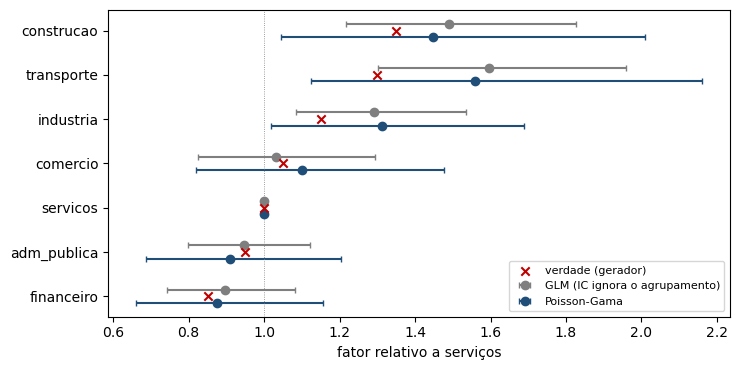

In [11]:
s = comp[comp["fator"] == "setor"].copy()
v = pd.Series({k: x["fator_mortalidade"] for k, x in cs["setores"].items()})
s["verdade"] = s["nivel"].map(v / v["servicos"])        # verdade relativa ao nível base (serviços)
s = s.sort_values("verdade")
fig, ax = plt.subplots(figsize=(7.5, 3.8)); y = np.arange(len(s))
ax.errorbar(s["relatividade_glm"], y + 0.15, xerr=[s["relatividade_glm"] - s["ic_inf_glm"], s["ic_sup_glm"] - s["relatividade_glm"]],
            fmt="o", color="#7f7f7f", capsize=2, label="GLM (IC ignora o agrupamento)")
ax.errorbar(s["relatividade_pg"], y - 0.15, xerr=[s["relatividade_pg"] - s["ic_inf_pg"], s["ic_sup_pg"] - s["relatividade_pg"]],
            fmt="o", color="#1f4e79", capsize=2, label="Poisson-Gama")
ax.scatter(s["verdade"], y, marker="x", color="#c00000", zorder=5, label="verdade (gerador)")
ax.set_yticks(y, s["nivel"]); ax.axvline(1, color="grey", lw=0.6, ls=":")
ax.set_xlabel("fator relativo a serviços"); ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

Os pontos estimados do GLM e do Poisson-Gama são parecidos. O que muda é o **intervalo**: o GLM trata
cada célula como independente e fica confiante demais, porque as células do mesmo grupo compartilham o
desvio do grupo. O estudo de simulação (seção 8) mede isso.

## 7. Quais fatores entram na tabela de preço

### 7.1 Seleção puramente estatística (referência)

In [12]:
sel_estat, hist_estat = M.selecionar_fatores(cel, F, alfa=cm["alfa_selecao"])
print("Seleção só por p-valor:", sel_estat)
hist_estat

Seleção só por p-valor: ['setor']


,fator,niveis,estatistica_lr,gl,p_valor,passo,acao
0,faixa_idade,5,3.2413,4,0.5183,1,
1,sexo,2,0.0026,1,0.9596,1,retirado
2,setor,7,17.4415,6,0.0078,1,
3,faixa_capital,5,1.8199,4,0.7688,1,
4,faixa_tamanho,4,1.1707,3,0.7600,1,
5,faixa_idade,5,3.2542,4,0.5162,2,
6,setor,7,17.7920,6,0.0068,2,
7,faixa_capital,5,1.8199,4,0.7688,2,retirado
8,faixa_tamanho,4,1.1706,3,0.7601,2,
9,faixa_idade,5,3.2641,4,0.5146,3,


Idade e sexo já estão na tábua; o teste mede só o desvio **adicional**. Na carteira deste notebook, a
seleção por p-valor fica só com o setor. Mas, no estudo de simulação (seção 8), com as **mesmas** hipóteses
e sementes diferentes, a mesma regra escolheu só setor em 9 de 12 carteiras, nenhum fator em uma, setor e
capital em outra e só capital na última. Com ~1.500 óbitos, a evidência dos fatores centrais oscila em
torno de 5%, e a estrutura da tabela de preço não pode mudar por isso.

### 7.2 Abordagem adotada: fatores de negócio com encolhimento

- **Setor e faixa de capital ficam na tabela** por decisão de negócio: atividade é fator de subscrição
  padrão; a mortalidade cai com o capital e o prêmio é em R$.
- São estimados com **encolhimento** para o nível base: penalização ridge no log do fator, que equivale a
  uma priori Normal(0, 1/λ). λ alto leva o fator a 1; λ = 0 é a estimativa livre. Cada fator tem o seu
  λ, escolhido por validação cruzada deixando grupos inteiros de fora (busca coordenada).
- Idade, sexo e porte continuam passando pelo teste de razão de verossimilhança.

In [13]:
obrig = cm["fatores_obrigatorios"]
selecionados, historico = M.selecionar_fatores(cel, F, alfa=cm["alfa_selecao"], obrigatorios=tuple(obrig))
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    lambdas, hist_lam = M.calibrar_encolhimento(cel, selecionados, obrig, cm["encolhimento"]["lambdas"],
                                                cm["encolhimento"]["folds"], cm["semente_cv"])
print("Fatores no modelo:", selecionados)
print("Encolhimento escolhido (lambda):", lambdas)
for a in avisos: print("AVISO:", a.message)
hist_lam[hist_lam["volta"] == 2].pivot(index="lambda", columns="fator", values="dif_vs_melhor")

Fatores no modelo: ['setor', 'faixa_capital']
Encolhimento escolhido (lambda): {'setor': 30.0, 'faixa_capital': 300.0}


fator,faixa_capital,setor
lambda,,
0.0000,3.9372,8.6641
1.0000,3.5617,7.7732
3.0000,3.0175,6.2938
10.0000,2.0189,2.9932
30.0000,0.9362,0.0000
100.0000,0.0931,2.0045
300.0000,0.0000,7.0121
"1,000.0000",0.2141,10.4134
"3,000.0000",0.3201,11.6310


A tabela mostra quanto a deviance fora da amostra piora em relação ao melhor λ de cada fator. Se o λ da
faixa de capital ficar no topo da grade, a leitura correta é: **com este volume de dados, o efeito de
capital não é estimável com precisão melhor do que ignorá-lo.** O fator continua na estrutura da tabela,
perto de 1, e se afasta de 1 sozinho quando a base tiver volume para isso, sem nova decisão de modelo.

### 7.3 Conferência: faixa de capital contra a verdade do gerador e em valor

In [14]:
det_v = V.detalhe_com_verdade(dados["vidas"], dados["estipulantes"], tabua, cfg["data_referencia"], cm,
                              verdade_vidas, cs, cfg["exposicao"]["dias_por_ano"])
base_cap = M.Desenho.criar(cel, ["faixa_capital"]).base["faixa_capital"]
modelo_final = M.ajustar_poisson_gama(cel, selecionados, penalizacao={f: l for f, l in lambdas.items() if l > 0} or None)
livre = M.ajustar_poisson_gama(cel, selecionados)
fc = lambda r: r.fatores().query("fator == 'faixa_capital'").set_index("nivel")["relatividade"]
ae = cel.groupby("faixa_capital").agg(E=("E", "sum"), N=("N", "sum"), VE=("valor_esperado", "sum"), VO=("valor_observado", "sum"))
ordem = cm["faixas"]["capital"]["rotulos"]
pd.DataFrame({"verdade (gerador)": V.relatividades_capital(det_v, base_cap),
              "estimativa livre": fc(livre), "estimativa encolhida": fc(modelo_final),
              "A/E contagem": ae["N"] / ae["E"], "A/E valor": ae["VO"] / ae["VE"], "óbitos": ae["N"]}).loc[ordem]

,verdade (gerador),estimativa livre,estimativa encolhida,A/E contagem,A/E valor,óbitos
ate30k,1.0205,1.1025,1.0353,1.0917,1.0769,364
30-60k,1.0000,1.0000,1.0000,0.9406,0.9343,530
60-150k,0.9767,1.0180,1.0000,0.9341,0.9447,381
150-400k,0.9169,0.9951,0.9951,0.8911,0.8756,107
acima400k,0.9058,0.8248,0.9900,0.7591,0.7368,14


O efeito verdadeiro é pequeno (poucos pontos percentuais entre faixas), e a estimativa livre oscila mais
que isso, principalmente nas faixas altas, com poucos óbitos. A estimativa encolhida fica perto de 1, que
aqui é o erro menor. O A/E em valor aponta na mesma direção que o de contagem, com ruído maior (poucos
sinistros de capital alto pesam muito), o que confirma a escolha de estimar em contagem.

## 8. Estudo de simulação: a complexidade muda o preço?

Doze carteiras sintéticas independentes, mesmas hipóteses, sementes diferentes
(`scripts/estudo_simulacao_manual.py`, ~8 minutos). Métricas:
- erro dos fatores de setor e de capital contra a verdade (RMSE em log);
- cobertura real do IC de 95% dos fatores de setor;
- **subsídio cruzado**: erro de estrutura do prêmio puro em R$, grupo a grupo, depois de igualar o nível
  da carteira (quanto um grupo paga por outro por erro da tabela);
- deviance deixando grupos inteiros de fora (o caso de uso da taxa manual: cotar um grupo novo).

In [15]:
est = pd.read_csv(RAIZ / "resultados/estudo_simulacao_manual.csv")
res_est = est.groupby("modelo").agg(erro_fatores_setor=("rmse_log_setor", "mean"),
                                    cobertura_ic95_setor=("cobertura_ic95_setor", "mean"),
                                    erro_fatores_capital=("rmse_log_capital", "mean"),
                                    subsidio_cruzado=("subsidio_cruzado", "mean"),
                                    deviance_grupos_novos=("deviance_fora_amostra", "mean"),
                                    k_medio=("k", "mean"))
res_est.sort_values("deviance_grupos_novos")

,erro_fatores_setor,cobertura_ic95_setor,erro_fatores_capital,subsidio_cruzado,deviance_grupos_novos,k_medio
modelo,,,,,,
"Poisson-Gama (setor + capital obrigatórios, encolhidos)",0.1039,0.9074,0.0796,0.0887,423.2281,12.0206
Poisson-Gama (selecionados),0.1308,0.9375,0.0828,0.1010,431.5264,12.4408
Ridge (todos),0.1148,NaN,0.0835,0.0967,434.0127,NaN
BR-EMS pura,0.1731,NaN,0.0802,0.1382,445.1298,NaN
Poisson-Gama (todos),0.1196,0.9259,0.1046,0.1060,453.3360,12.6425
NB2 (todos),0.1263,0.8519,0.1044,0.1113,455.0321,NaN
GLM (todos),0.1290,0.7963,0.1052,0.1141,455.6832,NaN


**Leitura** (médias de 12 carteiras):
- **GLM e NB2 com todos os fatores** preveem grupos novos *pior* que a própria tábua, e os intervalos de 95%
  acertam a verdade só ~80% (GLM) e ~85% (NB2) das vezes: tratam células do mesmo grupo como independentes.
- **Poisson-Gama com seleção por p-valor** melhora a previsão, mas herda a instabilidade da seleção.
- **Poisson-Gama com setor e capital obrigatórios e encolhidos** é o melhor em todas as métricas de preço:
  menor erro nos fatores de setor, **menor subsídio cruzado** e melhor previsão de grupos novos. A cobertura
  dos intervalos (~91%) fica um pouco abaixo da nominal, efeito conhecido do encolhimento (o intervalo é
  centrado na estimativa encolhida).
- **k:** em torno de 12, contra 10,6 implícito no gerador (efeito lognormal no gerador, Gama no modelo).
  Viés pequeno e conservador: k maior dá menos credibilidade à experiência.

**Decisão:** a taxa manual usa o Poisson-Gama com setor e faixa de capital obrigatórios e encolhidos, e os
demais fatores só com evidência estatística. A complexidade entra porque muda o preço: reduz o subsídio
cruzado e melhora a previsão de grupos novos. E o mesmo modelo entrega o k da renovação.

## 9. Modelo final e tabela de fatores para o cotador

In [16]:
final = modelo_final
meta = {"gerado_em": pd.Timestamp.today().date().isoformat(), "fonte_dados": "carteira sintética",
        "tabua": tabua.nome, "tabua_sha256": tabua.sha256, "corte_experiencia": info["corte_experiencia"],
        "obitos": info["obitos"], "esperados_tabua": round(info["esperados"], 2),
        "k_credibilidade": round(final.extra["k"], 3),
        "k_ic95": [round(x, 3) for x in final.extra["ic_k"]],
        "metodo_k": "máxima verossimilhança marginal (Bayes empírico); incerteza do k não propagada",
        "fatores_obrigatorios": obrig, "encolhimento_lambda": lambdas,
        "selecao_demais_fatores": f"razão de verossimilhança, alfa = {cm['alfa_selecao']}",
        "fatores_testados": F, "faixas": cm["faixas"]}
tabela = M.tabela_fatores(final, meta)
M.salvar_tabela(tabela, RAIZ / "artefatos/fatores_manual.yaml")
custo_v = V.custo_estrutural_por_grupo(det_v)
print("A/E base:", round(tabela["meta"]["ae_base"], 4))
print(f"Subsídio cruzado nesta carteira: modelo final {M.subsidio_cruzado(cel, final, custo_v):.3f} | "
      f"GLM com todos os fatores {M.subsidio_cruzado(cel, glm, custo_v):.3f}")
final.fatores()

A/E base: 0.9174
Subsídio cruzado nesta carteira: modelo final 0.054 | GLM com todos os fatores 0.088


,fator,nivel,base,relatividade,ep_log,ic_inf,ic_sup
0,setor,adm_publica,False,0.9169,0.1077,0.7424,1.1323
1,setor,comercio,False,0.9926,0.1095,0.8009,1.2301
2,setor,construcao,False,1.2057,0.1199,0.9532,1.5250
3,setor,financeiro,False,0.8679,0.1082,0.7020,1.0730
4,setor,industria,False,1.1519,0.0989,0.9489,1.3984
5,setor,servicos,True,1.0000,0.0000,1.0000,1.0000
6,setor,transporte,False,1.2733,0.1184,1.0096,1.6058
7,faixa_capital,150-400k,False,0.9951,0.0507,0.9010,1.0990
8,faixa_capital,30-60k,True,1.0000,0.0000,1.0000,1.0000
9,faixa_capital,60-150k,False,1.0000,0.0451,0.9155,1.0923


## 10. Exemplo: taxa pura manual de um grupo

In [17]:
ref = pd.Timestamp(cfg["data_referencia"])
ativos = dados["vidas"][dados["vidas"]["data_fim"].isna()]
grupos = ativos["id_estipulante"].value_counts()
grupo = grupos.index[len(grupos) // 2]                                  # um grupo de porte mediano
censo = ativos[ativos["id_estipulante"] == grupo]
setor = dados["estipulantes"].set_index("id_estipulante").loc[grupo, "setor"]
cot = M.taxa_pura_manual(censo, setor, tabela, tabua, ref + pd.Timedelta(days=1), cm)
pd.Series({"estipulante": grupo, "setor": setor, "vidas": cot["vidas"], "capital total (R$)": cot["capital_total"],
           "óbitos esperados/ano": cot["obitos_esperados"], "prêmio puro anual (R$)": cot["premio_puro_anual"],
           "taxa pura anual (‰)": cot["taxa_pura_anual_mil"], "taxa pura mensal (‰)": cot["taxa_pura_mensal_mil"],
           "níveis sem fator": cot["niveis_sem_fator"] or "nenhum"}).to_frame("cotação")

,cotação
estipulante,EST0192
setor,industria
vidas,293
capital total (R$),"29,300,000.0000"
óbitos esperados/ano,0.6947
prêmio puro anual (R$),"69,471.7466"
taxa pura anual (‰),2.3710
taxa pura mensal (‰),0.1976
níveis sem fator,nenhum


A taxa comercial (carregamentos, impostos, corretagem) e o reajuste de renovação entram no cotador e na
Etapa 3.

## Limitações
- **Dados sintéticos:** os fatores refletem as hipóteses do gerador. Com a base real, o mesmo procedimento
  roda de novo; o código não muda.
- **Poder estatístico:** com ~1.500 óbitos, o efeito de capital fica abaixo do ruído e o fator sai perto de
  1. Com mais volume, o mesmo procedimento deixa o fator se afastar de 1.
- **Intervalos com encolhimento:** centrados na estimativa encolhida; cobertura ~91% no estudo.
- **k por Bayes empírico:** a incerteza do k não está no preço (Etapa 4).
- **Efeito Gama vs lognormal:** o modelo assume Gama; o estudo mostra viés pequeno e conservador no k.
- **Porte do grupo:** sem efeito na mortalidade. Se o mercado diferencia preço por porte, isso é despesa
  (carregamento), não mortalidade, e vai como parâmetro no cotador.